# EN3160 Assignment 2

- Name: Tharushika G.K.E.
- Index number: 230636K
- GitHub link: https://github.com/ErandiTharushika/A02-Fitting-and-Alignment

### Question 1

In [101]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

Libraries loaded successfully


Displaying the image

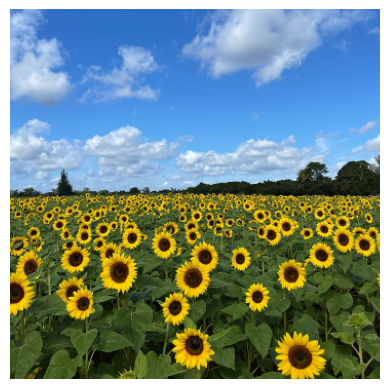

In [102]:
im = cv.imread(
    "a2images/the_berry_farms_sunflower_field.jpeg",
    cv.IMREAD_REDUCED_COLOR_4
)

plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [103]:
sigmas = np.arange(1, 21)

image = im.astype(np.float64) / 255.0
responses = []

for sigma in sigmas:
    blurred = cv.GaussianBlur(image, (0, 0), float(sigma))
    log = sigma**2 * cv.Laplacian(blurred, cv.CV_64F)

    response = np.maximum(np.sum(log, axis=2), 0)**2
    responses.append(response)

responses = np.stack(responses, axis=2)

print("LoG completed")

LoG completed


In [104]:
from scipy.ndimage import maximum_filter

local_max = maximum_filter(responses, size=(3, 3, 3))

threshold = 0.65 * responses.max()
peaks = (responses == local_max) & (responses > threshold)

peaks[:, :, 0] = False
peaks[:, :, -1] = False

ys, xs, scale_ids = np.where(peaks)

print("Number of detected blobs:", len(xs))

Number of detected blobs: 43


Drawing the detected circles

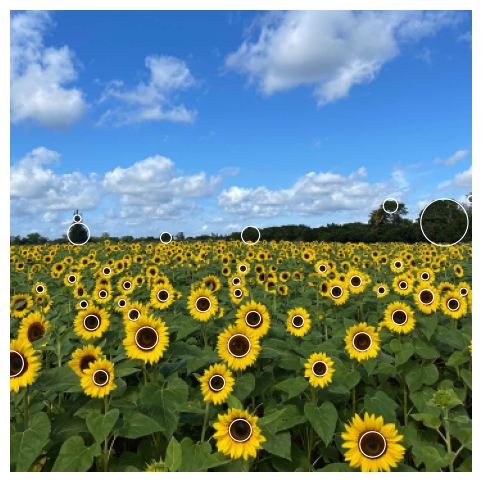

In [105]:
radii = np.sqrt(2) * sigmas[scale_ids]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for x, y, radius in zip(xs, ys, radii):
    circle = plt.Circle(
        (x, y), radius,
        color="white", fill=False, linewidth=0.8
    )
    ax.add_patch(circle)

ax.axis("off")
plt.show()

Parameters of the largest circles and range of σ values

In [106]:
largest = np.argsort(radii)[::-1][:5]

print("   x     y    radius   sigma")

for i in largest:
    sigma = sigmas[scale_ids[i]]
    print(f"{xs[i]:4d}  {ys[i]:4d}  {radii[i]:8.2f}  {sigma:6.2f}")

   x     y    radius   sigma
 338   165     18.38   13.00
   0   275      9.90    7.00
 282   338      9.90    7.00
 106   255      8.49    6.00
 178   261      8.49    6.00


In [107]:
fig.savefig("output/q1_circles.png", dpi=300, bbox_inches="tight")

### Question 2

Generating the noisy circle and line points

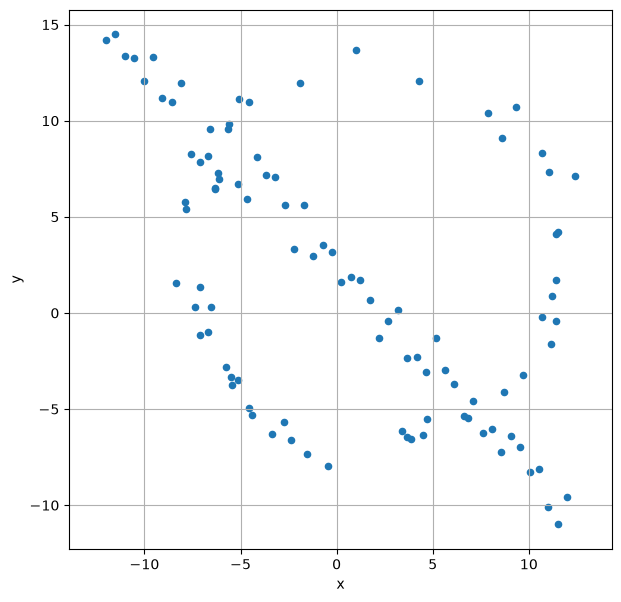

In [108]:
np.random.seed(0)

N = 100
half_n = N // 2

# Circle points
r = 10
x0_gt, y0_gt = 2, 3

t = np.random.uniform(0, 2 * np.pi, half_n)
n = (r / 16) * np.random.randn(half_n)

x = x0_gt + (r + n) * np.cos(t)
y = y0_gt + (r + n) * np.sin(t)

X_circ = np.column_stack((x, y))

# Line points
m, b = -1, 2

x = np.linspace(-12, 12, half_n)
y = m * x + b + np.random.randn(half_n)

X_line = np.column_stack((x, y))

# Combine all points
X = np.vstack((X_circ, X_line))

plt.figure(figsize=(7, 7))

plt.scatter(X[:, 0], X[:, 1], s=20)

plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.grid()
plt.show()

(a) Estimating the line using the RANSAC algorithm 

In [109]:
def line_from_two(points):
    x1, y1 = points[0]
    x2, y2 = points[1]

    a = y1 - y2
    b = x2 - x1

    length = np.hypot(a, b)

    if length < 1e-10:
        return None

    a, b = a / length, b / length
    d = a * x1 + b * y1

    if d < 0:
        a, b, d = -a, -b, -d

    return np.array([a, b, d])

In [110]:
rng = np.random.default_rng(1)

threshold_line = 1.4
min_inliers_line = 35
iterations = 2000

best_line = None
best_line_inliers = np.zeros(len(X), dtype=bool)
best_line_sample = None

for _ in range(iterations):
    indices = rng.choice(len(X), 2, replace=False)
    sample = X[indices]

    model = line_from_two(sample)

    if model is None:
        continue

    a, b, d = model
    errors = np.abs(a * X[:, 0] + b * X[:, 1] - d)
    inliers = errors < threshold_line

    count = np.sum(inliers)

    if count >= min_inliers_line and count > np.sum(best_line_inliers):
        best_line = model
        best_line_inliers = inliers
        best_line_sample = sample

if best_line is None:
    raise ValueError("No suitable line consensus found.")

print("Sample line parameters:", best_line)
print("Number of line inliers:", np.sum(best_line_inliers))

Sample line parameters: [0.70012561 0.7140197  1.57504464]
Number of line inliers: 55


Fitting a better line using all consensus points

In [111]:
line_points = X[best_line_inliers]

centre = line_points.mean(axis=0)

_, _, Vt = np.linalg.svd(line_points - centre)
normal = Vt[-1]

d = normal @ centre

if d < 0:
    normal = -normal
    d = -d

fitted_line = np.array([normal[0], normal[1], d])

print("Best-fit line parameters:", fitted_line)
print("Normal length:", np.linalg.norm(normal))

Best-fit line parameters: [0.71666967 0.69741278 1.50289658]
Normal length: 0.9999999999999999


(b) Removing the line consensus

In [112]:
X_remaining = X[~best_line_inliers]

print("Remaining points:", len(X_remaining))

Remaining points: 45


Defining a circle from three noncollinear points

In [113]:
def circle_from_three(points):
    p1, p2, p3 = points

    A = 2 * np.array([p2 - p1, p3 - p1])

    B = np.array([
        np.sum(p2**2) - np.sum(p1**2),
        np.sum(p3**2) - np.sum(p1**2)
    ])

    if abs(np.linalg.det(A)) < 1e-10:
        return None

    centre = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - centre)

    return np.array([centre[0], centre[1], radius])

Applying RANSAC to the remaining points using radial distance error.

In [114]:
rng = np.random.default_rng(2)

threshold_circle = 1.5
min_inliers_circle = 25
iterations_circle = 3000

best_circle = None
best_circle_inliers = np.zeros(len(X_remaining), dtype=bool)
best_circle_sample = None

for _ in range(iterations_circle):
    indices = rng.choice(len(X_remaining), 3, replace=False)
    sample = X_remaining[indices]

    model = circle_from_three(sample)

    if model is None:
        continue

    cx, cy, radius = model

    distances = np.sqrt(
        (X_remaining[:, 0] - cx)**2 +
        (X_remaining[:, 1] - cy)**2
    )

    errors = np.abs(distances - radius)
    inliers = errors < threshold_circle

    count = np.sum(inliers)

    if count >= min_inliers_circle and count > np.sum(best_circle_inliers):
        best_circle = model
        best_circle_inliers = inliers
        best_circle_sample = sample

if best_circle is None:
    raise ValueError("No suitable circle consensus found.")

print("Sample circle parameters:", best_circle)
print("Number of circle inliers:", np.sum(best_circle_inliers))

Sample circle parameters: [2.19856394 3.02138053 9.85345618]
Number of circle inliers: 45


Refining the circle using consensus points.

In [115]:
from scipy.optimize import minimize

circle_points = X_remaining[best_circle_inliers]

def circle_cost(parameters):
    cx, cy, radius = parameters

    distances = np.sqrt(
        (circle_points[:, 0] - cx)**2 +
        (circle_points[:, 1] - cy)**2
    )

    return np.sum((distances - radius)**2)

result = minimize(
    circle_cost,
    best_circle,
    method="L-BFGS-B",
    bounds=[(None, None), (None, None), (0.001, None)]
)

if not result.success:
    raise ValueError(result.message)

fitted_circle = result.x

print("Best-fit circle parameters:", fitted_circle)

Best-fit circle parameters: [1.86292004 3.07477151 9.95344386]


Q2(c): Final results

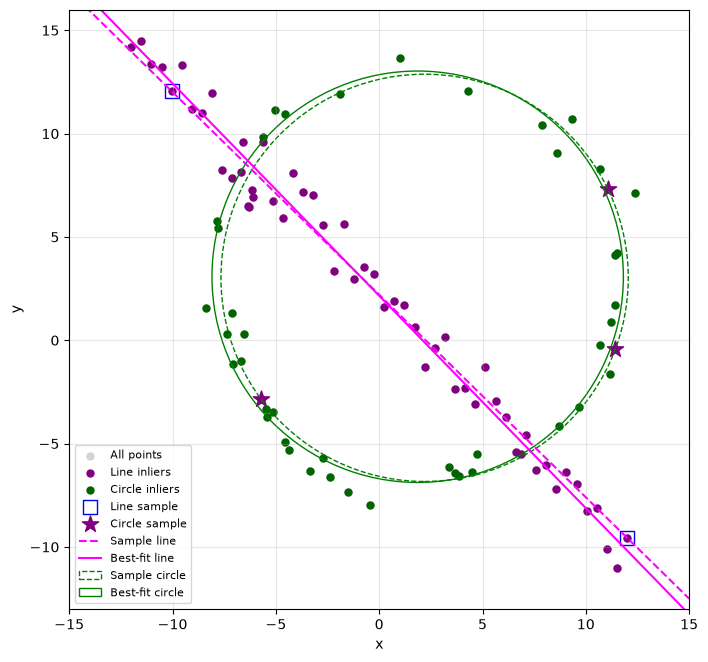

In [116]:
fig, ax = plt.subplots(figsize=(8, 8))

# All points and the two consensuses
ax.scatter(X[:, 0], X[:, 1],
           color="lightgray", s=25, label="All points")

ax.scatter(line_points[:, 0], line_points[:, 1],
           color="purple", s=25, label="Line inliers")

ax.scatter(circle_points[:, 0], circle_points[:, 1],
           color="darkgreen", s=25, label="Circle inliers")

# Winning sample points
ax.scatter(best_line_sample[:, 0], best_line_sample[:, 1],
           marker="s", s=100, facecolors="none",
           edgecolors="blue", label="Line sample")

ax.scatter(best_circle_sample[:, 0], best_circle_sample[:, 1],
           marker="*", s=150, color="purple", label="Circle sample")

# Sample line and best-fit line
xx = np.array([-15, 15])

for model, style, label in [
    (best_line, "--", "Sample line"),
    (fitted_line, "-", "Best-fit line")
]:
    a, b, d = model
    ax.plot(xx, (d - a * xx) / b,
            color="magenta", linestyle=style, label=label)

# Sample circle and best-fit circle
for model, style, label in [
    (best_circle, "--", "Sample circle"),
    (fitted_circle, "-", "Best-fit circle")
]:
    cx, cy, radius = model
    ax.add_patch(plt.Circle(
        (cx, cy), radius, fill=False,
        color="green", linestyle=style, label=label
    ))

ax.set_aspect("equal")
ax.set_xlim(-15, 15)
ax.set_ylim(-13, 16)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=8)

fig.savefig("output/q2_ransac.png", dpi=300, bbox_inches="tight")
plt.show()

(d) If we create Circle first RANSAC can still find the correct circle, but it has some risks:
- A circle with a very large radius can approximate a straight line, so line points may form a false circle consensus.
- Line points near the true circle may be classified as circle inliers. Removing them leaves fewer points for the later line fit.
Therefore, the fitting order can affect the result; fitting the circle first does not necessarily fail.

### Question 3

Implementing the Example

In [117]:
background = cv.imread("a2images/wadham.jpg")
overlay = cv.imread("a2images/flag.png")

corners = []
preview = background.copy()

def select_corner(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(corners) < 4:
        corners.append([x, y])
        cv.circle(preview, (x, y), 5, (0, 0, 255), -1)

cv.namedWindow("Select corners", cv.WINDOW_NORMAL)
cv.setMouseCallback("Select corners", select_corner)

while len(corners) < 4:
    cv.imshow("Select corners", preview)
    if cv.waitKey(20) == 27:
        break

cv.destroyAllWindows()
print(corners)

[[155, 208], [522, 292], [131, 445], [509, 465]]


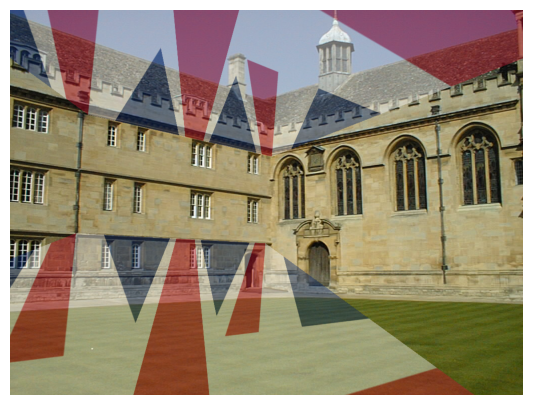

True

In [118]:
assert len(corners) == 4, "Select four corners first."

h, w = overlay.shape[:2]

source = np.float32([
    [0, 0], [w - 1, 0],
    [w - 1, h - 1], [0, h - 1]
])

H = cv.getPerspectiveTransform(source, np.float32(corners))
size = (background.shape[1], background.shape[0])

warped = cv.warpPerspective(overlay, H, size)

mask = np.full((h, w), 255, dtype=np.uint8)
mask = cv.warpPerspective(mask, H, size, flags=cv.INTER_NEAREST)

blended = cv.addWeighted(background, 0.6, warped, 0.4, 0)
result = background.copy()
result[mask > 0] = blended[mask > 0]

plt.figure(figsize=(8, 5))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

cv.imwrite("output/q3_pair1.png", result)

Implementing with another image

In [119]:
background = cv.imread("a2images/uom.jpeg")
overlay = cv.imread("a2images/logo.png")

corners = []
preview = background.copy()

def select_corner(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(corners) < 4:
        corners.append([x, y])
        cv.circle(preview, (x, y), 5, (0, 0, 255), -1)

cv.namedWindow("Select corners", cv.WINDOW_NORMAL)
cv.setMouseCallback("Select corners", select_corner)

while len(corners) < 4:
    cv.imshow("Select corners", preview)
    if cv.waitKey(20) == 27:
        break

cv.destroyAllWindows()
print(corners)

[[235, 238], [336, 243], [334, 351], [233, 356]]


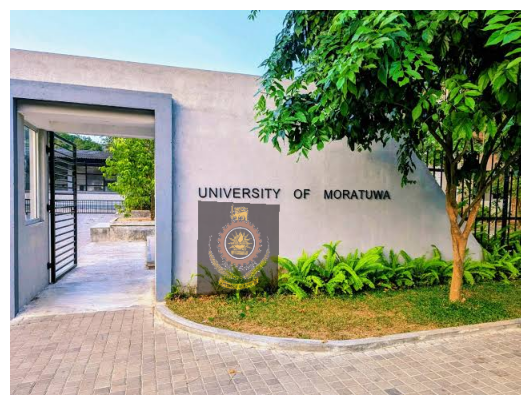

True

In [120]:
assert len(corners) == 4, "Select four corners first."

h, w = overlay.shape[:2]

source = np.float32([
    [0, 0], [w - 1, 0],
    [w - 1, h - 1], [0, h - 1]
])

H = cv.getPerspectiveTransform(source, np.float32(corners))
size = (background.shape[1], background.shape[0])

warped = cv.warpPerspective(overlay, H, size)

mask = np.full((h, w), 255, dtype=np.uint8)
mask = cv.warpPerspective(mask, H, size, flags=cv.INTER_NEAREST)

blended = cv.addWeighted(background, 0.5, warped, 0.5, 0)
result = background.copy()
result[mask > 0] = blended[mask > 0]

plt.figure(figsize=(8, 5))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

cv.imwrite("output/q3_pair2.png", result)

### Question 4

(a): Detecting SIFT features

In [121]:
template = cv.imread("a2images/pcbs/AECC1.jpg")
pcb = cv.imread("a2images/pcbs/AAAA1.jpg")

template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
pcb_gray = cv.cvtColor(pcb, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()

kp_template, des_template = sift.detectAndCompute(template_gray, None)
kp_pcb, des_pcb = sift.detectAndCompute(pcb_gray, None)

print("Template keypoints:", len(kp_template))
print("PCB keypoints:", len(kp_pcb))

Template keypoints: 14272
PCB keypoints: 2414


Matching the SIFT features

In [122]:
matcher = cv.BFMatcher(cv.NORM_L2)

matches = matcher.knnMatch(des_pcb, des_template, k=2)

good_matches = []

for pair in matches:
    if len(pair) == 2:
        first, second = pair

        if first.distance < 0.75 * second.distance:
            good_matches.append(first)

print("Matches after filtering:", len(good_matches))

Matches after filtering: 51


Estimating the homography with RANSAC

In [123]:
pcb_points = np.float32([
    kp_pcb[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

template_points = np.float32([
    kp_template[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

H_pcb, match_inliers = cv.findHomography(
    pcb_points, template_points,
    cv.RANSAC, 5.0
)

if H_pcb is None:
    raise ValueError("Homography estimation failed.")

print("RANSAC inlier matches:", int(match_inliers.sum()))

RANSAC inlier matches: 18


Matched features across 2 images

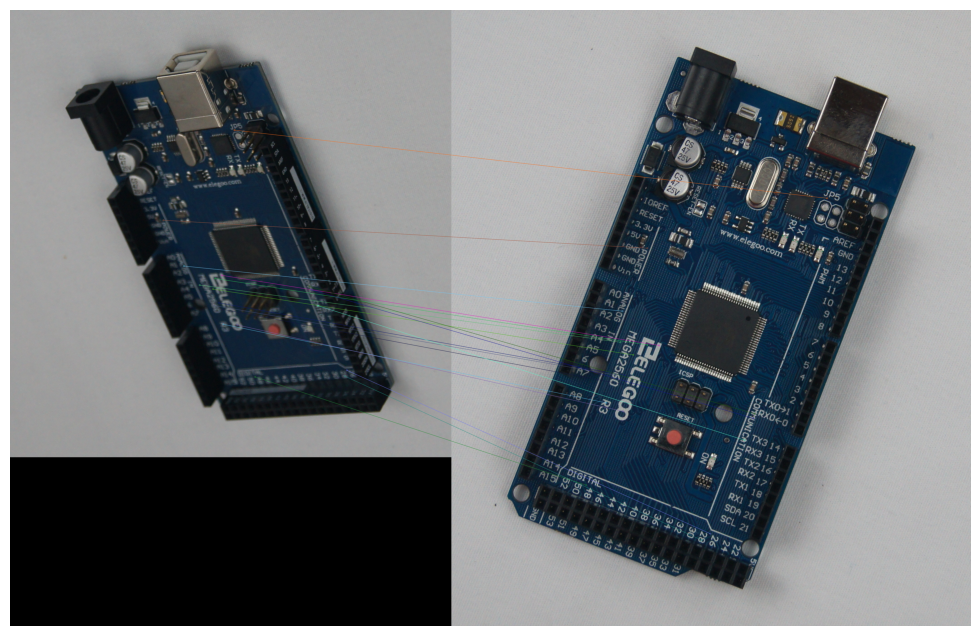

True

In [124]:
match_image = cv.drawMatches(
    pcb, kp_pcb,
    template, kp_template,
    good_matches, None,
    matchesMask=match_inliers.ravel().tolist(),
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(14, 8))
plt.imshow(cv.cvtColor(match_image, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

cv.imwrite("output/q4_AAAA1_matches.jpg", match_image)

(c) Warping the image

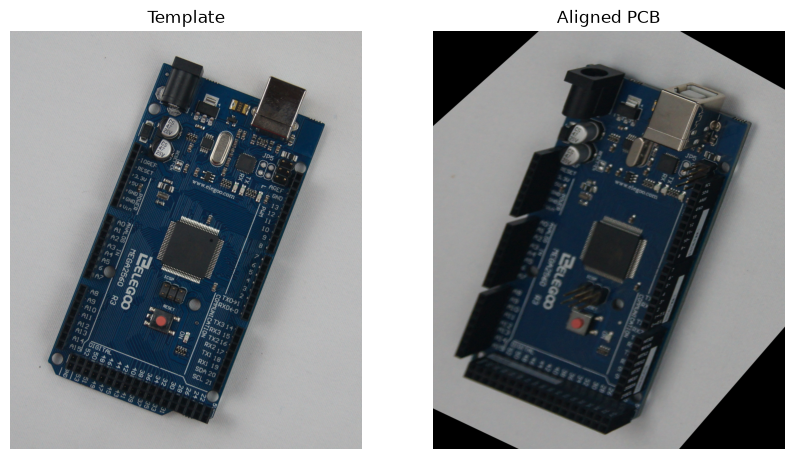

In [125]:
height, width = template.shape[:2]

aligned_pcb = cv.warpPerspective(
    pcb, H_pcb, (width, height)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
axes[0].set_title("Template")

axes[1].imshow(cv.cvtColor(aligned_pcb, cv.COLOR_BGR2RGB))
axes[1].set_title("Aligned PCB")

for ax in axes:
    ax.axis("off")

plt.show()

Difference image

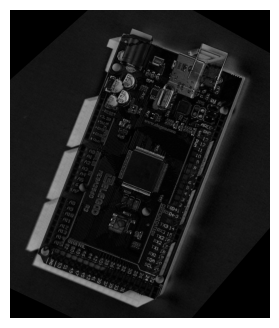

True

In [126]:
aligned_gray = cv.cvtColor(aligned_pcb, cv.COLOR_BGR2GRAY)

difference = cv.absdiff(template_gray, aligned_gray)

valid_mask = cv.warpPerspective(
    np.ones(pcb_gray.shape, dtype=np.uint8),
    H_pcb, (width, height),
    flags=cv.INTER_NEAREST
)

difference[valid_mask == 0] = 0

plt.figure(figsize=(4, 4))
plt.imshow(difference, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

cv.imwrite("output/q4_AAAA1_difference.png", difference)

(d) Repeating the procedure for other PCBs

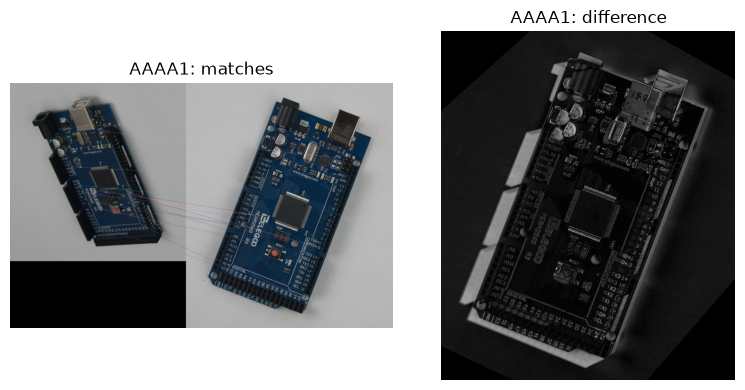

AAAA1: 51 matches, 18 RANSAC inliers


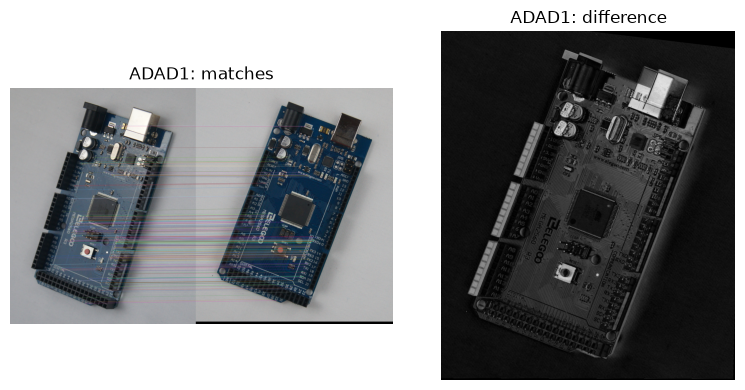

ADAD1: 369 matches, 194 RANSAC inliers


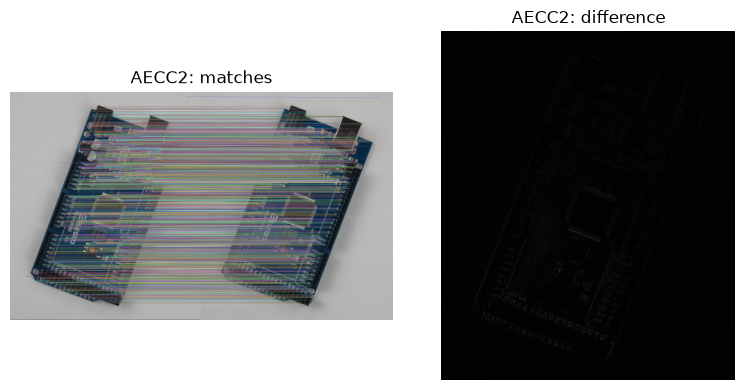

AECC2: 4322 matches, 3847 RANSAC inliers


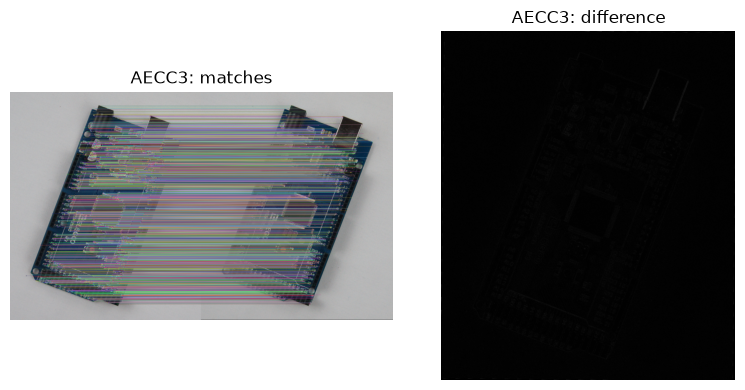

AECC3: 5629 matches, 5006 RANSAC inliers


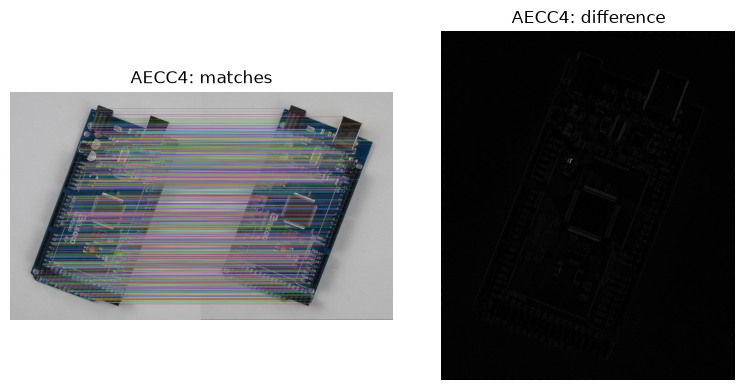

AECC4: 3830 matches, 3402 RANSAC inliers


In [127]:
# Prepare the template once
template = cv.imread("a2images/pcbs/AECC1.jpg")
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp_template, des_template = sift.detectAndCompute(template_gray, None)

matcher = cv.BFMatcher(cv.NORM_L2)
height, width = template.shape[:2]

names = ["AAAA1", "ADAD1", "AECC2", "AECC3", "AECC4"]

for name in names:
    # Detect SIFT features
    pcb = cv.imread(f"a2images/pcbs/{name}.jpg")
    pcb_gray = cv.cvtColor(pcb, cv.COLOR_BGR2GRAY)
    kp_pcb, des_pcb = sift.detectAndCompute(pcb_gray, None)

    # Match features and apply the ratio test
    matches = matcher.knnMatch(des_pcb, des_template, k=2)

    good_matches = []
    for pair in matches:
        if len(pair) == 2:
            first, second = pair
            if first.distance < 0.75 * second.distance:
                good_matches.append(first)

    if len(good_matches) < 4:
        print(name, ": Not enough matches.")
        continue

    # Estimate the homography using RANSAC
    pcb_points = np.float32([
        kp_pcb[m.queryIdx].pt for m in good_matches
    ]).reshape(-1, 1, 2)

    template_points = np.float32([
        kp_template[m.trainIdx].pt for m in good_matches
    ]).reshape(-1, 1, 2)

    H_pcb, inliers = cv.findHomography(
        pcb_points, template_points, cv.RANSAC, 5.0
    )

    if H_pcb is None:
        print(name, ": Homography failed.")
        continue

    # Draw the accepted matches
    match_image = cv.drawMatches(
        pcb, kp_pcb, template, kp_template,
        good_matches, None,
        matchesMask=inliers.ravel().tolist(),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Align the PCB and calculate the difference
    aligned = cv.warpPerspective(pcb, H_pcb, (width, height))
    aligned_gray = cv.cvtColor(aligned, cv.COLOR_BGR2GRAY)

    difference = cv.absdiff(template_gray, aligned_gray)

    # Exclude areas outside the warped source image
    valid_mask = cv.warpPerspective(
        np.ones(pcb_gray.shape, dtype=np.uint8),
        H_pcb, (width, height),
        flags=cv.INTER_NEAREST
    )
    difference[valid_mask == 0] = 0

    # Display results
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(cv.cvtColor(match_image, cv.COLOR_BGR2RGB))
    axes[0].set_title(f"{name}: matches")

    axes[1].imshow(difference, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title(f"{name}: difference")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # Save results
    cv.imwrite(f"output/q4_{name}_matches.jpg", match_image)
    cv.imwrite(f"output/q4_{name}_difference.png", difference)

    print(f"{name}: {len(good_matches)} matches, "
          f"{int(inliers.sum())} RANSAC inliers")

(e) why do the USB port, capacitors and reset button show high differences?

These components extend above the PCB surface, while the homography aligns only the board’s plane. Changes in camera viewpoint therefore cause parallax, leaving the raised components misaligned. Lighting changes, reflections and shadows can also increase their differences.